Clasificación de defectos superficiales en acero
**Visión Artificial · Entrega 3 · ITM**

**Pipeline:** extracción de características (HOG, LBP, GLCM y fusión) → normalización Z-score → clasificación (k-NN, SVM, Random Forest) → benchmark.

**Integrantes:** 
Samuel Álvarez Mejía,
Juan Miguel Jiménez Chavarriaga,
Juan Camilo Montoya Jaramillo

## 0. Librerías


In [1]:
import os
import time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Importaciones de skimage para descriptores de características
from skimage.feature import hog, local_binary_pattern, graycomatrix, graycoprops

## 1. Carga de imágenes


In [2]:
# >>> AJUSTA ESTAS RUTAS <<<
base_dir = r"C:\Users\petuc\OneDrive\Desktop\Vision 3\Vision 3\NEU-DET\NEU-DET"
output_dir = r"C:\Users\petuc\OneDrive\Desktop\Vision 3\Vision 3\Resultados vision"
os.makedirs(output_dir, exist_ok=True)

clases = ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
extensiones = ('.jpg', '.jpeg', '.png', '.bmp')

def cargar_imagenes_validas(path, files, n=300):
    imgs = []
    for f in files:
        img = cv2.imread(os.path.join(path, f))
        if img is not None:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            imgs.append(img)
        if len(imgs) == n:
            break
    return imgs

def normalizar_imagenes(imgs, size=(128, 128)):
    imgs_norm = []
    for img in imgs:
        if img is not None:
            img_resized = cv2.resize(img, size)
            img_norm = img_resized.astype("float32") / 255.0
            imgs_norm.append(img_norm)
    return np.array(imgs_norm)

X_list, y_list = [], []
for etiqueta, clase in enumerate(clases):
    path_clase = os.path.join(base_dir, clase)
    files = sorted([f for f in os.listdir(path_clase) if f.lower().endswith(extensiones)])
    imgs = cargar_imagenes_validas(path_clase, files, 300)
    imgs_norm = normalizar_imagenes(imgs)
    X_list.append(imgs_norm)
    y_list.append(np.full(len(imgs_norm), etiqueta))
    print(f"{clase}: {len(imgs_norm)} imágenes")

X = np.concatenate(X_list, axis=0)
y = np.concatenate(y_list, axis=0)

crazing: 300 imágenes
inclusion: 300 imágenes
patches: 300 imágenes
pitted_surface: 300 imágenes
rolled-in_scale: 300 imágenes
scratches: 300 imágenes


## 2. Los 6 defectos

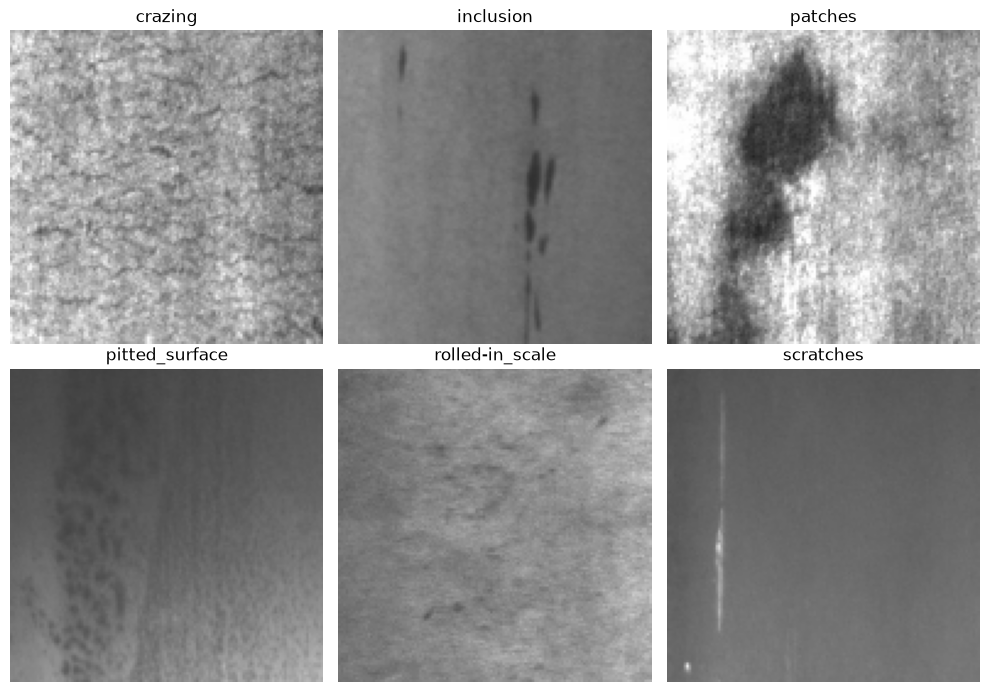

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for k, ax in enumerate(axes.ravel()):
    idx = np.where(y == k)[0][0]
    ax.imshow(X[idx])
    ax.set_title(clases[k])
    ax.axis('off')
plt.tight_layout()
plt.show()

## 3. División entrenamiento / validación 

In [4]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
print(f"Dataset listo -> Train: {X_train.shape}, Validación: {X_val.shape}")

Dataset listo -> Train: (1260, 128, 128, 3), Validación: (540, 128, 128, 3)


## 4. Descriptores: HOG, LBP y GLCM

In [5]:
# HOG (Histogram of Oriented Gradients)
def extraer_hog(imagenes):
    hog_features = []
    for img in imagenes:
        img_gray = cv2.cvtColor((img * 255).astype("uint8"), cv2.COLOR_RGB2GRAY)
        features = hog(img_gray, orientations=9, pixels_per_cell=(8, 8),
                       cells_per_block=(2, 2), block_norm='L2-Hys', visualize=False)
        hog_features.append(features)
    return np.array(hog_features)

# LBP (Local Binary Patterns)
def extraer_lbp(imagenes, P=8, R=1):
    lbp_features = []
    for img in imagenes:
        img_gray = cv2.cvtColor((img * 255).astype("uint8"), cv2.COLOR_RGB2GRAY)
        lbp = local_binary_pattern(img_gray, P=P, R=R, method="uniform")
        # Construcción del histograma de patrones invariantes
        (hist, _) = np.histogram(lbp.ravel(), bins=np.arange(0, P + 3), range=(0, P + 2))
        hist = hist.astype("float32")
        hist /= (hist.sum() + 1e-7)  # Normalización del histograma LBP
        lbp_features.append(hist)
    return np.array(lbp_features)

# GLCM (Gray-Level Co-occurrence Matrix)
def extraer_glcm(imagenes, distances=[1, 3], angles=[0, np.pi/4, np.pi/2, 3*np.pi/4]):
    glcm_features = []
    propiedades = ['contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation', 'ASM']
    for img in imagenes:
        img_gray = cv2.cvtColor((img * 255).astype("uint8"), cv2.COLOR_RGB2GRAY)
        # Matriz de coocurrencia (escalada a 64 niveles de gris para acelerar el cálculo)
        img_gray_q = (img_gray // 4).astype(np.uint8)
        glcm = graycomatrix(img_gray_q, distances=distances, angles=angles, levels=64, symmetric=True, normed=True)

        vector_img = []
        for prop in propiedades:
            valores = graycoprops(glcm, prop).ravel()
            vector_img.extend(valores)
        glcm_features.append(vector_img)
    return np.array(glcm_features)

## 5. Extracción de características

In [6]:
print("\nExtrayendo HOG...")
X_train_hog = extraer_hog(X_train)
X_val_hog = extraer_hog(X_val)

print("Extrayendo LBP...")
X_train_lbp = extraer_lbp(X_train)
X_val_lbp = extraer_lbp(X_val)

print("Extrayendo GLCM...")
X_train_glcm = extraer_glcm(X_train)
X_val_glcm = extraer_glcm(X_val)

print(f"\nDimensiones resultantes:")
print(f"HOG  -> Train: {X_train_hog.shape}")
print(f"LBP  -> Train: {X_train_lbp.shape}")
print(f"GLCM -> Train: {X_train_glcm.shape}")


Extrayendo HOG...
Extrayendo LBP...
Extrayendo GLCM...

Dimensiones resultantes:
HOG  -> Train: (1260, 8100)
LBP  -> Train: (1260, 10)
GLCM -> Train: (1260, 48)


## 6. Visualización de los descriptores

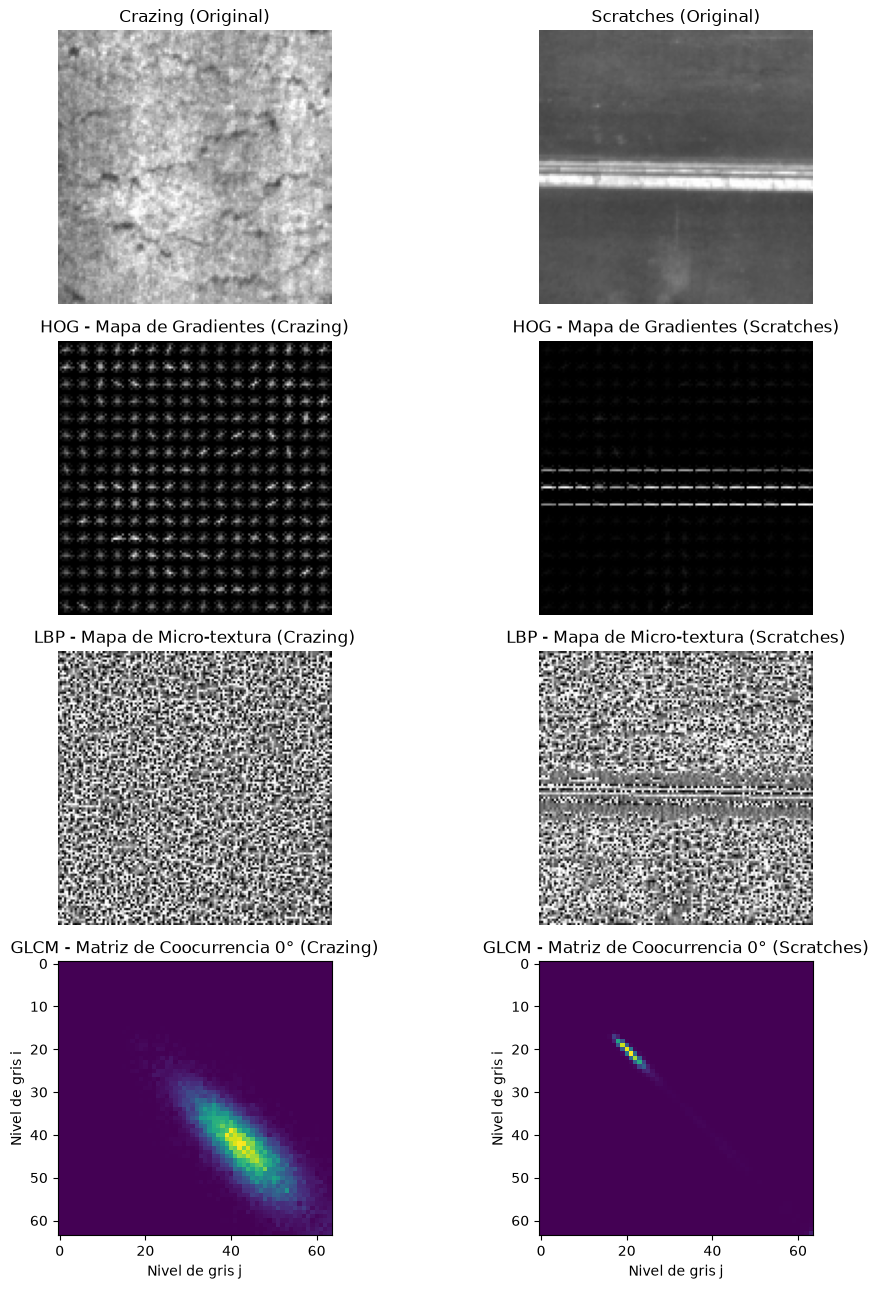

In [7]:
idx_a = np.where(y_val == 0)[0][0]   # crazing
idx_b = np.where(y_val == 5)[0][0]   # scratches

img_a_gray = cv2.cvtColor((X_val[idx_a] * 255).astype("uint8"), cv2.COLOR_RGB2GRAY)
img_b_gray = cv2.cvtColor((X_val[idx_b] * 255).astype("uint8"), cv2.COLOR_RGB2GRAY)

# Cálculo de mapas visuales
_, hog_a_vis = hog(img_a_gray, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), visualize=True)
_, hog_b_vis = hog(img_b_gray, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), visualize=True)

lbp_a_vis = local_binary_pattern(img_a_gray, P=8, R=1, method="uniform")
lbp_b_vis = local_binary_pattern(img_b_gray, P=8, R=1, method="uniform")

# GLCM (Matriz 2D a distancia 1, ángulo 0°)
a_q = (img_a_gray // 4).astype(np.uint8)
b_q = (img_b_gray // 4).astype(np.uint8)
glcm_a_vis = graycomatrix(a_q, distances=[1], angles=[0], levels=64, symmetric=True, normed=True)[:, :, 0, 0]
glcm_b_vis = graycomatrix(b_q, distances=[1], angles=[0], levels=64, symmetric=True, normed=True)[:, :, 0, 0]

fig1, axes1 = plt.subplots(4, 2, figsize=(11, 13))

axes1[0, 0].imshow(X_val[idx_a]); axes1[0, 0].set_title("Crazing (Original)"); axes1[0, 0].axis('off')
axes1[0, 1].imshow(X_val[idx_b]); axes1[0, 1].set_title("Scratches (Original)"); axes1[0, 1].axis('off')

axes1[1, 0].imshow(hog_a_vis, cmap='gray'); axes1[1, 0].set_title("HOG - Mapa de Gradientes (Crazing)"); axes1[1, 0].axis('off')
axes1[1, 1].imshow(hog_b_vis, cmap='gray'); axes1[1, 1].set_title("HOG - Mapa de Gradientes (Scratches)"); axes1[1, 1].axis('off')

axes1[2, 0].imshow(lbp_a_vis, cmap='gray'); axes1[2, 0].set_title("LBP - Mapa de Micro-textura (Crazing)"); axes1[2, 0].axis('off')
axes1[2, 1].imshow(lbp_b_vis, cmap='gray'); axes1[2, 1].set_title("LBP - Mapa de Micro-textura (Scratches)"); axes1[2, 1].axis('off')

axes1[3, 0].imshow(glcm_a_vis, cmap='viridis'); axes1[3, 0].set_title("GLCM - Matriz de Coocurrencia 0° (Crazing)")
axes1[3, 0].set_xlabel("Nivel de gris j"); axes1[3, 0].set_ylabel("Nivel de gris i")
axes1[3, 1].imshow(glcm_b_vis, cmap='viridis'); axes1[3, 1].set_title("GLCM - Matriz de Coocurrencia 0° (Scratches)")
axes1[3, 1].set_xlabel("Nivel de gris j"); axes1[3, 1].set_ylabel("Nivel de gris i")

plt.tight_layout()
plt.show()

## 7. Fusión y normalización Z-score

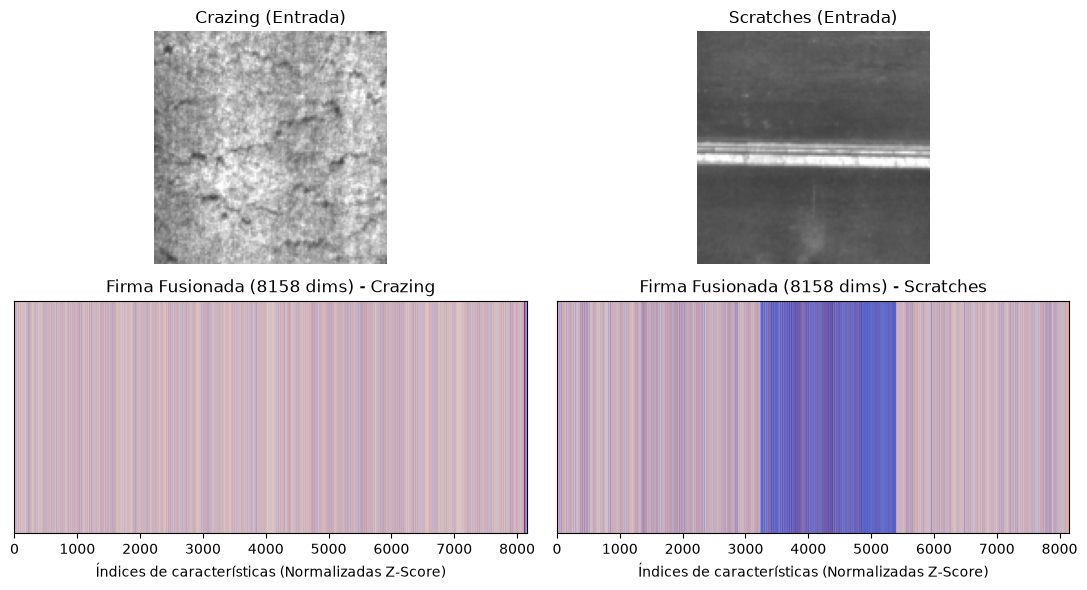

Vector Fusionado y Escalado -> Train: (1260, 8158), Val: (540, 8158)


In [8]:
# Fusión de los tres descriptores
X_train_fusion = np.hstack((X_train_hog, X_train_lbp, X_train_glcm))
X_val_fusion = np.hstack((X_val_hog, X_val_lbp, X_val_glcm))

scaler = StandardScaler()
X_train_fusion_scaled = scaler.fit_transform(X_train_fusion)
X_val_fusion_scaled = scaler.transform(X_val_fusion)

# Fusión solo de textura (LBP + GLCM)
X_train_tex = np.hstack((X_train_lbp, X_train_glcm))
X_val_tex = np.hstack((X_val_lbp, X_val_glcm))

scaler_tex = StandardScaler()
X_train_tex_scaled = scaler_tex.fit_transform(X_train_tex)
X_val_tex_scaled = scaler_tex.transform(X_val_tex)

# Firma fusionada de las dos imágenes de ejemplo
fusion_a_vis = X_val_fusion_scaled[idx_a].reshape(1, -1)
fusion_b_vis = X_val_fusion_scaled[idx_b].reshape(1, -1)

fig2, axes2 = plt.subplots(2, 2, figsize=(11, 6))
axes2[0, 0].imshow(X_val[idx_a]); axes2[0, 0].set_title("Crazing (Entrada)"); axes2[0, 0].axis('off')
axes2[0, 1].imshow(X_val[idx_b]); axes2[0, 1].set_title("Scratches (Entrada)"); axes2[0, 1].axis('off')

axes2[1, 0].imshow(fusion_a_vis, aspect='auto', cmap='coolwarm', vmin=-2, vmax=2)
axes2[1, 0].set_title(f"Firma Fusionada ({fusion_a_vis.shape[1]} dims) - Crazing")
axes2[1, 0].set_yticks([]); axes2[1, 0].set_xlabel("Índices de características (Normalizadas Z-Score)")

axes2[1, 1].imshow(fusion_b_vis, aspect='auto', cmap='coolwarm', vmin=-2, vmax=2)
axes2[1, 1].set_title(f"Firma Fusionada ({fusion_b_vis.shape[1]} dims) - Scratches")
axes2[1, 1].set_yticks([]); axes2[1, 1].set_xlabel("Índices de características (Normalizadas Z-Score)")

plt.tight_layout()
plt.show()

print(f"Vector Fusionado y Escalado -> Train: {X_train_fusion_scaled.shape}, Val: {X_val_fusion_scaled.shape}")

## 8. Escalado individual y guardado de características

In [9]:
# Escaladores independientes para cada conjunto individual
scaler_hog = StandardScaler()
X_tr_hog_sc = scaler_hog.fit_transform(X_train_hog)
X_va_hog_sc = scaler_hog.transform(X_val_hog)

scaler_lbp = StandardScaler()
X_tr_lbp_sc = scaler_lbp.fit_transform(X_train_lbp)
X_va_lbp_sc = scaler_lbp.transform(X_val_lbp)

scaler_glcm = StandardScaler()
X_tr_glcm_sc = scaler_glcm.fit_transform(X_train_glcm)
X_va_glcm_sc = scaler_glcm.transform(X_val_glcm)

# Guardado en formato .npz comprimido
np.savez_compressed(os.path.join(output_dir, "features_hog.npz"),
                    X_train=X_tr_hog_sc, X_val=X_va_hog_sc, y_train=y_train, y_val=y_val)
np.savez_compressed(os.path.join(output_dir, "features_lbp.npz"),
                    X_train=X_tr_lbp_sc, X_val=X_va_lbp_sc, y_train=y_train, y_val=y_val)
np.savez_compressed(os.path.join(output_dir, "features_glcm.npz"),
                    X_train=X_tr_glcm_sc, X_val=X_va_glcm_sc, y_train=y_train, y_val=y_val)
np.savez_compressed(os.path.join(output_dir, "features_fusion.npz"),
                    X_train=X_train_fusion_scaled, X_val=X_val_fusion_scaled, y_train=y_train, y_val=y_val)
np.savez_compressed(os.path.join(output_dir, "features_textura.npz"),
                    X_train=X_train_tex_scaled, X_val=X_val_tex_scaled, y_train=y_train, y_val=y_val)

print("Características guardadas exitosamente")

Características guardadas exitosamente


## 9. Benchmark: clasificadores × descriptores

In [10]:
features_dir = output_dir

feature_files = {
    'HOG': 'features_hog.npz',
    'LBP': 'features_lbp.npz',
    'GLCM': 'features_glcm.npz',
    'LBP+GLCM (textura)': 'features_textura.npz',
    'FUSIÓN (HOG+LBP+GLCM)': 'features_fusion.npz'
}

models = {
    'k-NN (k=5)': KNeighborsClassifier(n_neighbors=5, metric='euclidean'),
    'SVM (RBF)': SVC(kernel='rbf', C=1.0, probability=True, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
}

results = []
predicciones = {}

print("Iniciando Benchmark de Modelos y Descriptores...\n")

for feat_name, file_name in feature_files.items():
    path = os.path.join(features_dir, file_name)
    data = np.load(path)

    X_train_f, X_val_f = data['X_train'], data['X_val']
    y_train_f, y_val_f = data['y_train'], data['y_val']

    for model_name, model in models.items():
        t0 = time.time()

        # Entrenamiento
        model.fit(X_train_f, y_train_f)

        # Predicción
        t1 = time.time()
        y_pred = model.predict(X_val_f)
        t_exec = time.time() - t0
        t_pred_ms = (time.time() - t1) / len(y_val_f) * 1000

        # Métricas de Evaluación
        acc = accuracy_score(y_val_f, y_pred)
        prec = precision_score(y_val_f, y_pred, average='macro')
        rec = recall_score(y_val_f, y_pred, average='macro')
        f1 = f1_score(y_val_f, y_pred, average='macro')

        predicciones[(feat_name, model_name)] = (y_val_f, y_pred)
        results.append({
            'Descriptor': feat_name,
            'Modelo': model_name,
            'Dimensiones': X_train_f.shape[1],
            'Accuracy': acc,
            'Precision': prec,
            'Recall': rec,
            'F1-Score': f1,
            'Tiempo (s)': t_exec,
            'Predicción (ms/img)': t_pred_ms
        })
        print(f"{feat_name} | {model_name} -> F1={f1:.3f}")

df_results = pd.DataFrame(results)

print("=" * 85)
print("TABLA CONSOLIDADA DE BENCHMARK (DEFECTOS SUPERFICIALES EN ACERO - NEU)")
print("=" * 85)
print(df_results.round(3).to_string(index=False))

df_results.to_csv(os.path.join(os.path.dirname(output_dir), "benchmark_resultados.csv"), index=False)

Iniciando Benchmark de Modelos y Descriptores...

HOG | k-NN (k=5) -> F1=0.590


C:\Users\petuc\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


HOG | SVM (RBF) -> F1=0.852
HOG | Random Forest -> F1=0.703
LBP | k-NN (k=5) -> F1=0.868


C:\Users\petuc\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


LBP | SVM (RBF) -> F1=0.888
LBP | Random Forest -> F1=0.878
GLCM | k-NN (k=5) -> F1=0.908
GLCM | SVM (RBF) -> F1=0.883


...

GLCM | Random Forest -> F1=0.931
LBP+GLCM (textura) | k-NN (k=5) -> F1=0.935
LBP+GLCM (textura) | SVM (RBF) -> F1=0.953


C:\Users\petuc\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


LBP+GLCM (textura) | Random Forest -> F1=0.948
FUSIÓN (HOG+LBP+GLCM) | k-NN (k=5) -> F1=0.612


C:\Users\petuc\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


FUSIÓN (HOG+LBP+GLCM) | SVM (RBF) -> F1=0.885
FUSIÓN (HOG+LBP+GLCM) | Random Forest -> F1=0.871
TABLA CONSOLIDADA DE BENCHMARK (DEFECTOS SUPERFICIALES EN ACERO - NEU)
           Descriptor        Modelo  Dimensiones  Accuracy  Precision  Recall  F1-Score  Tiempo (s)  Predicción (ms/img)
                  HOG    k-NN (k=5)         8100     0.641      0.757   0.641     0.590       0.207                0.365
                  HOG     SVM (RBF)         8100     0.856      0.857   0.856     0.852      53.891               11.988
                  HOG Random Forest         8100     0.715      0.720   0.715     0.703       1.423                0.069
                  LBP    k-NN (k=5)           10     0.869      0.874   0.869     0.868       0.015                0.010
                  LBP     SVM (RBF)           10     0.889      0.892   0.889     0.888       0.319                0.179
                  LBP Random Forest           10     0.878      0.879   0.878     0.878       0.196        

## 10. Gráfica comparativa

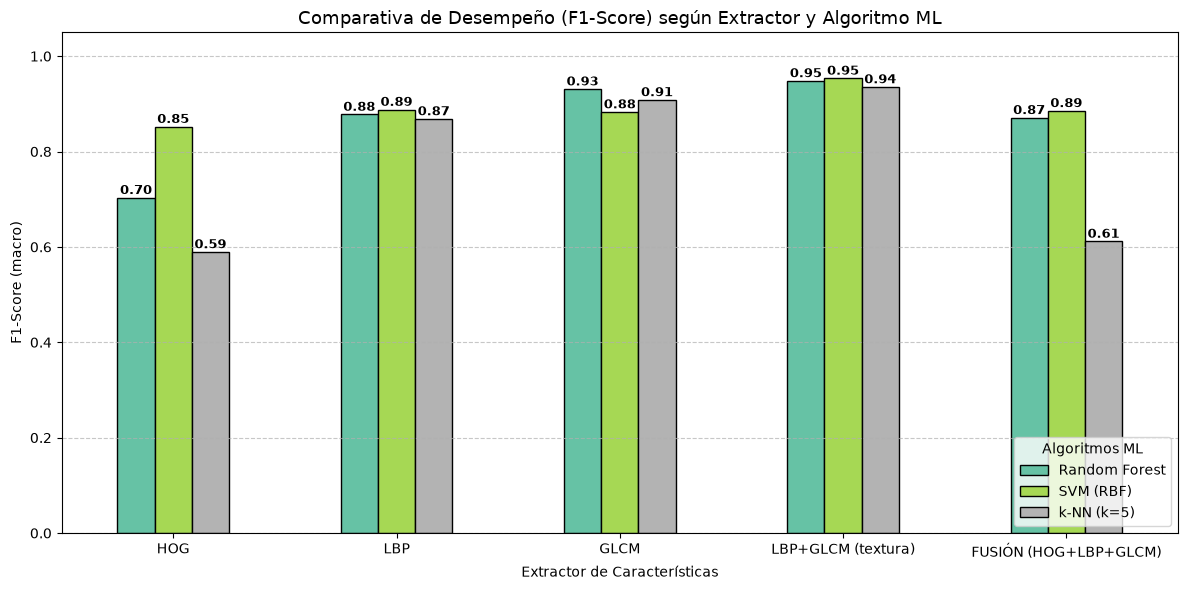

In [11]:
df_pivot = df_results.pivot(index='Descriptor', columns='Modelo', values='F1-Score')
df_pivot = df_pivot.loc[list(feature_files.keys())]

ax = df_pivot.plot(kind='bar', figsize=(12, 6), colormap='Set2', edgecolor='black')
plt.title("Comparativa de Desempeño (F1-Score) según Extractor y Algoritmo ML", fontsize=13)
plt.ylabel("F1-Score (macro)")
plt.xlabel("Extractor de Características")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title="Algoritmos ML", loc='lower right')

for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f"{p.get_height():.2f}",
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center', xytext=(0, 5),
                    textcoords='offset points', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

## 11. Métricas de negocio del mejor modelo

MEJOR COMBINACIÓN: LBP+GLCM (textura) + SVM (RBF)
  Accuracy: 95.4% | F1 macro: 0.953
  Predicción: 0.041 ms por imagen (sin contar la extracción)


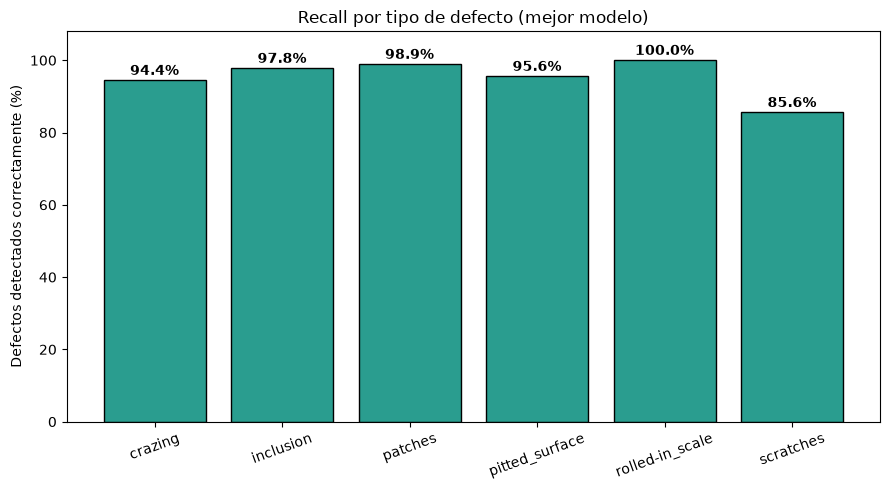

In [12]:
mejor = df_results.sort_values('F1-Score', ascending=False).iloc[0]
print(f"MEJOR COMBINACIÓN: {mejor['Descriptor']} + {mejor['Modelo']}")
print(f"  Accuracy: {mejor['Accuracy']*100:.1f}% | F1 macro: {mejor['F1-Score']:.3f}")
print(f"  Predicción: {mejor['Predicción (ms/img)']:.3f} ms por imagen (sin contar la extracción)")

y_true_m, y_pred_m = predicciones[(mejor['Descriptor'], mejor['Modelo'])]
recall_clase = recall_score(y_true_m, y_pred_m, average=None)

plt.figure(figsize=(9, 5))
barras = plt.bar(clases, recall_clase * 100, color='#2a9d8f', edgecolor='black')
plt.ylim(0, 108)
plt.ylabel("Defectos detectados correctamente (%)")
plt.title("Recall por tipo de defecto (mejor modelo)")
plt.xticks(rotation=20)
for b, v in zip(barras, recall_clase):
    plt.text(b.get_x() + b.get_width() / 2, v * 100 + 1.5, f"{v*100:.1f}%", ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

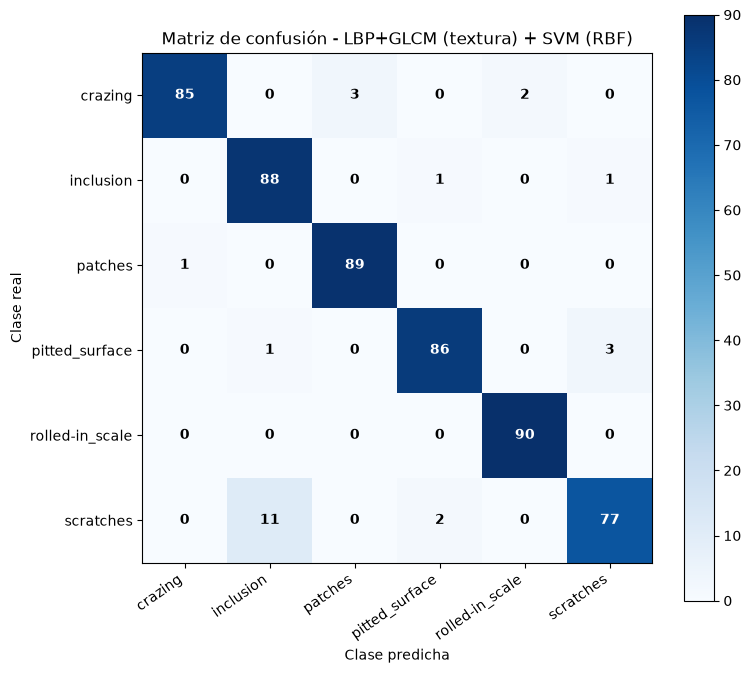

Confusión más frecuente: 'scratches' predicho como 'inclusion' (11 casos)


In [13]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true_m, y_pred_m)

plt.figure(figsize=(8, 7))
plt.imshow(cm, cmap='Blues')
plt.title(f"Matriz de confusión - {mejor['Descriptor']} + {mejor['Modelo']}")
plt.colorbar()
plt.xticks(range(len(clases)), clases, rotation=35, ha='right')
plt.yticks(range(len(clases)), clases)
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
for i in range(len(clases)):
    for j in range(len(clases)):
        plt.text(j, i, cm[i, j], ha='center', va='center', fontweight='bold',
                 color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.tight_layout()
plt.show()

# Par de clases que más se confunde
cm_err = cm.copy()
np.fill_diagonal(cm_err, 0)
i, j = np.unravel_index(cm_err.argmax(), cm_err.shape)
print(f"Confusión más frecuente: '{clases[i]}' predicho como '{clases[j]}' ({cm_err[i, j]} casos)")